In [23]:
from src.structures import M2PlusGenerator
import yaml
from copy import deepcopy
from src.structures.visualisation import plot_generated_sites, show_structure

In [27]:
with open("configs/structure_generation.yaml") as f:
    config = yaml.safe_load(f)

test_config = deepcopy(config)

test_config["frameworks"]["codes"] = ["FAU"]

test_config["species"]["M2+"]["enabled"] = True
test_config["species"]["M2+"]["metals"] = ["Cu"]
test_config["species"]["M2+"]["ring_sizes"] = [4, 6, 8]

test_config["enumeration"]["max_al_distance"] = None
test_config["enumeration"]["one_per_pair_ring"] = True

test_config["validation"]["retain_failed_structures"] = True
test_config["output"]["directory"] = "data/generated_structures/test_Cu_CHA"

In [28]:
generator = M2PlusGenerator(test_config)
structures = generator.generate()

Generating FAU / Cu²⁺
  11 structures


ZSE identified rings: {4: 144, 5: 0, 6: 64, 7: 0, 8: 96}


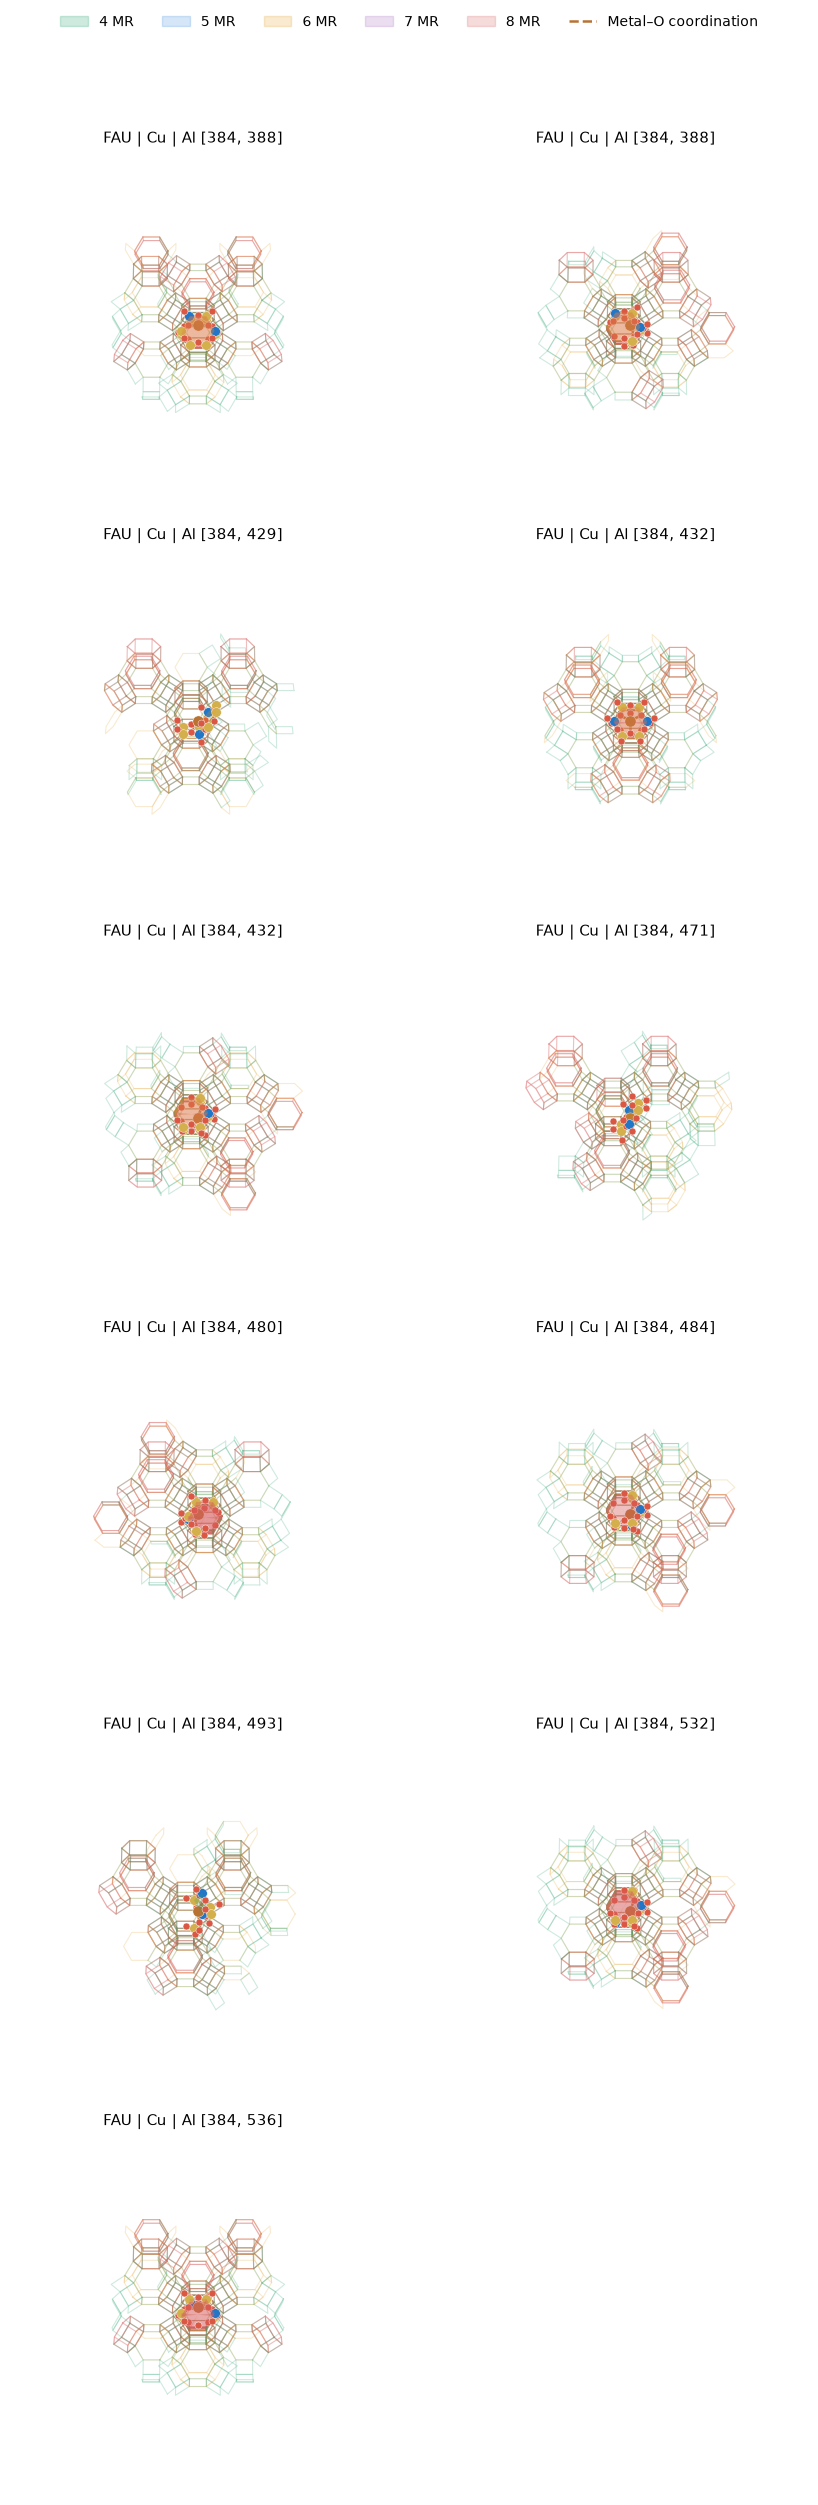

In [35]:
fig = plot_generated_sites(
    structures,
    radius=4.5,
    context_radius=20,
    framework_context=True,
    ring_overlays=True,
    ring_sizes=(4, 5, 6, 7, 8),
    ncols=2,
)
# plt.show()

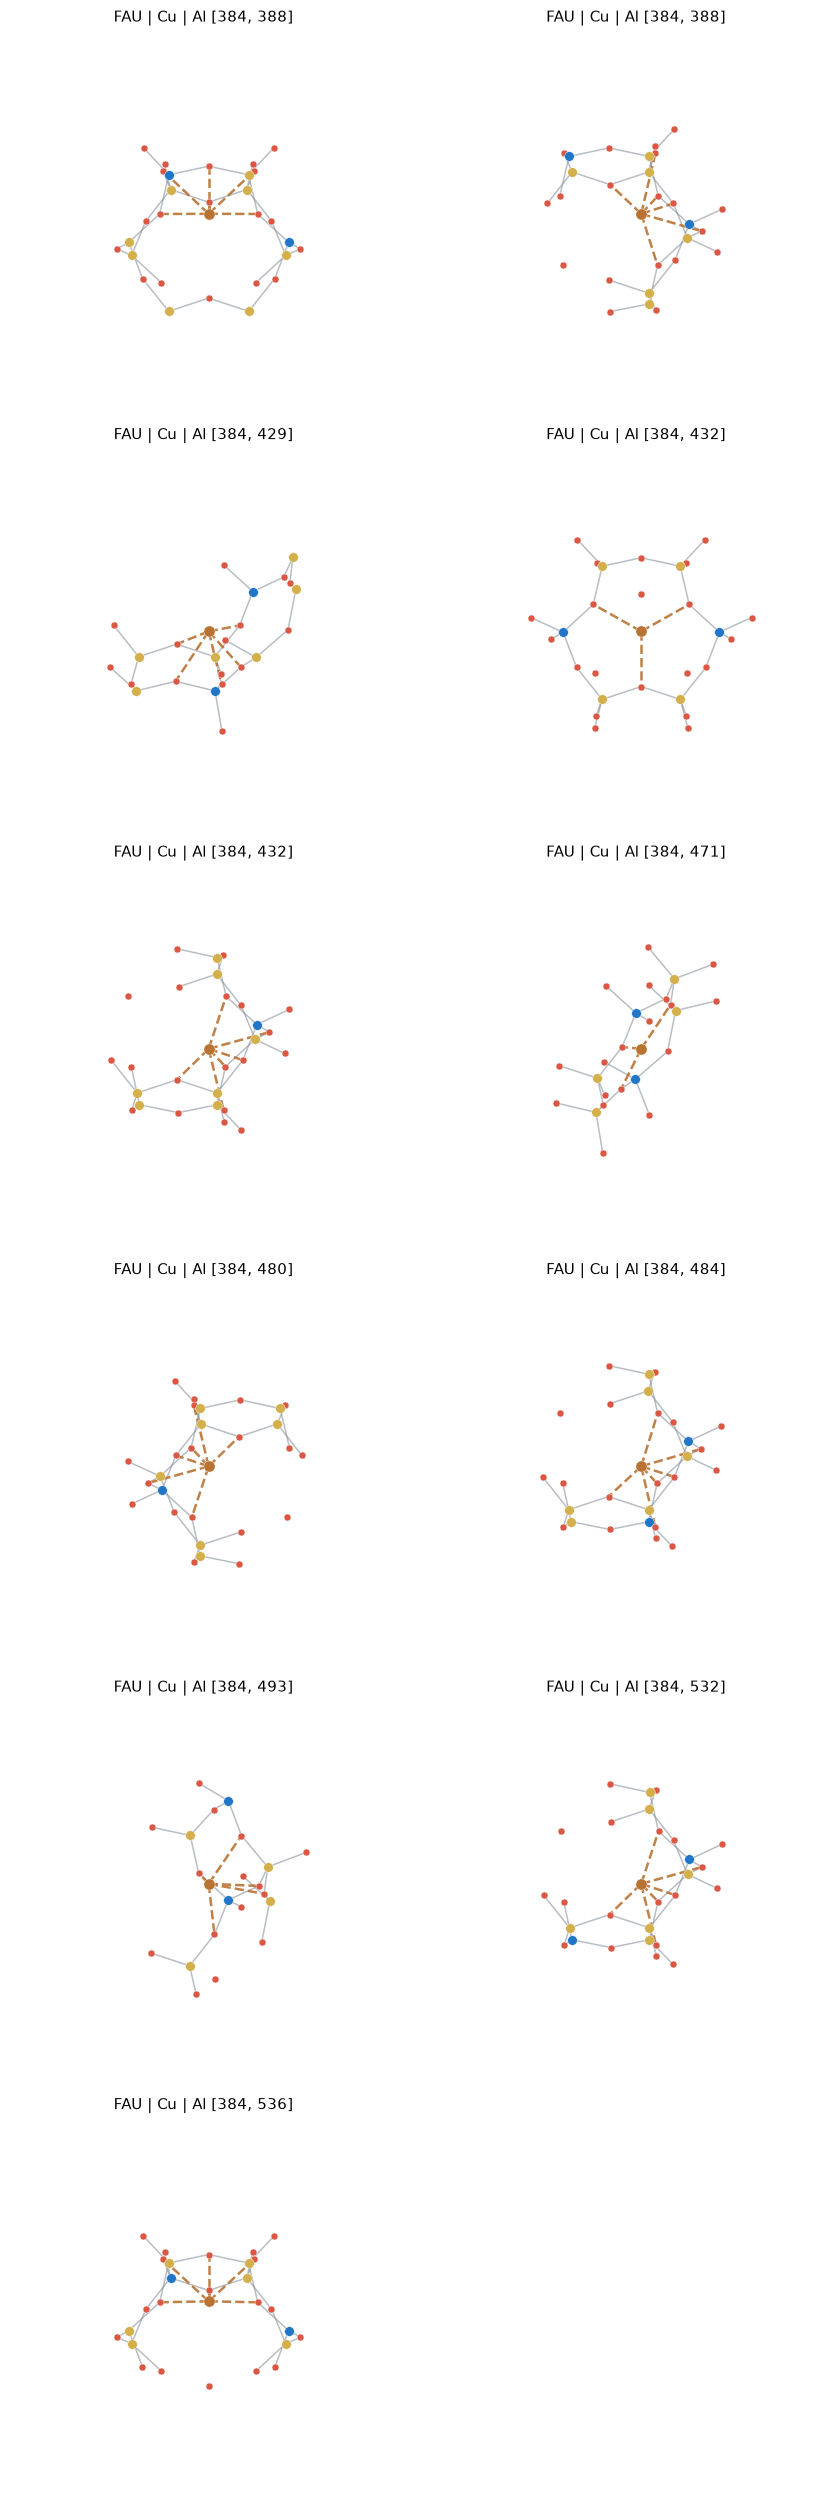

In [30]:
fig = plot_generated_sites(
    structures,
    radius=4.5,
    framework_context=False,
    ring_overlays=False,
    ring_sizes=(4, 5, 6),
    ncols=2
)

In [31]:
summary = generator.summary(structures)
summary.columns

Index(['site_id', 'framework', 'cation', 'cation_charge', 'efw_site_type',
       'chemical_formula', 'n_atoms', 'n_framework_al', 'al_indices',
       'al_al_distance_A', 'al_pair_multiplicity', 'lowenstein_valid',
       'shared_ring_sizes', 'n_shared_rings', 'six_mr_arrangements',
       'source_ring_size', 'source_ring_t_indices', 'source_ring_o_indices',
       'generation_ring_sizes', 'placement_method', 'metal_position_cart_A',
       'metal_position_frac', 'coordination_number', 'min_mo_A', 'min_mt_A',
       'metal_o_clash', 'metal_t_clash', 'steric_clash', 'low_coordination',
       'n_al_adjacent_o', 'n_si_o_si', 'coordinating_oxygens',
       'placement_score', 'constraint_violation', 'optimizer_converged',
       'placement_feasible', 'optimizer_message', 'placement_success',
       'geometry_status'],
      dtype='str')

In [32]:
import pandas as pd

rows = []

for atoms in structures:
    metadata = atoms.info["metadata"]
    al1, al2 = metadata["al_indices"]
    cu = len(atoms) - 1

    coordinating = metadata["geometry"]["coordinating_oxygens"]

    rows.append({
        "site_id": metadata["site_id"],
        "al_pair": (al1, al2),
        "source_ring": metadata["source_ring_size"],
        "Cu_Al1_A": round(atoms.get_distance(cu, al1, mic=True), 3),
        "Cu_Al2_A": round(atoms.get_distance(cu, al2, mic=True), 3),
        "Cu_Al_difference_A": round(abs(
            atoms.get_distance(cu, al1, mic=True)
            - atoms.get_distance(cu, al2, mic=True)
        ), 3),
        "O_near_Al1": sum(al1 in o["t_indices"] for o in coordinating),
        "O_near_Al2": sum(al2 in o["t_indices"] for o in coordinating),
        "Cu_O_coordination": len(coordinating),
        "status": metadata["geometry"]["geometry_status"]
    })

asymmetry_df = pd.DataFrame(rows)
display(asymmetry_df.sort_values("Cu_Al_difference_A", ascending=False))

,site_id,al_pair,source_ring,Cu_Al1_A,Cu_Al2_A,Cu_Al_difference_A,O_near_Al1,O_near_Al2,Cu_O_coordination,status
6,FAU_Cu_M2_0006,"(384, 480)",8,4.656,2.400,2.256,0,3,6,ok
4,FAU_Cu_M2_0004,"(384, 432)",8,2.400,4.541,2.141,3,0,6,ok
9,FAU_Cu_M2_0009,"(384, 532)",8,2.400,3.779,1.379,3,0,6,ok
1,FAU_Cu_M2_0001,"(384, 388)",8,2.581,3.778,1.197,2,0,6,ok
0,FAU_Cu_M2_0000,"(384, 388)",6,3.596,2.400,1.196,1,3,6,ok
2,FAU_Cu_M2_0002,"(384, 429)",6,3.563,2.400,1.163,1,3,5,ok
10,FAU_Cu_M2_0010,"(384, 536)",8,3.625,2.615,1.010,1,2,6,ok
8,FAU_Cu_M2_0008,"(384, 493)",4,2.400,3.372,0.972,3,1,5,ok
7,FAU_Cu_M2_0007,"(384, 484)",4,2.400,2.567,0.167,3,2,6,ok
3,FAU_Cu_M2_0003,"(384, 432)",6,3.079,3.079,0.000,1,1,3,ok


In [33]:
show_structure(structures[0], repeat=(1,1,1))

NGLWidget()

In [36]:
import os

files = os.listdir("data/zeolite_cifs")
len(files)

42